# 🕵️ Image Forgery Detection — ELA + Copy-Move + ML
**Goal:** Detect whether an image has been tampered with, and *where*.

Two classic forgery types are covered:
- **Splicing** — a region pasted from a *different* photo → detected with **Error Level Analysis (ELA)** + a Random Forest.
- **Copy-move** — a region duplicated *inside the same* image → detected with **SIFT keypoint self-matching + RANSAC**.

> ⚠️ The dataset is **synthetic**: I generate forgeries myself from 6 natural photos (see `src/make_dataset.py`), so I know the exact ground-truth masks. Results show the method works on a controlled benchmark — they are **not** a claim about real-world forgery detection.

In [1]:
import sys, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
sys.path.insert(0, "src")
from forgery_utils import *
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi":110, "axes.titleweight":"bold"})
SAVE = lambda n: plt.savefig(f"images/{n}.png", bbox_inches="tight")
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
SEED = 42

## 1. Dataset
1,200 images of 256×256 px. Every image gets a **prior JPEG history (q=70)**, is optionally tampered, and is finally saved at **q=95** — mimicking photos that were compressed before being edited and re-saved. Splice donors always come from a *different* photo; copy-move regions are optionally rotated (±15°) and rescaled (0.9–1.1×).

In [2]:
df = pd.read_csv("data/labels.csv")
print(df.type.value_counts().to_dict(), "\n", df.groupby(["source","type"]).size().unstack())

{'authentic': 600, 'splicing': 300, 'copy-move': 300} 
 type       authentic  copy-move  splicing
source                                   
astronaut        100         50        50
chelsea          100         50        50
china            100         50        50
coffee           100         50        50
flower           100         50        50
rocket           100         50        50


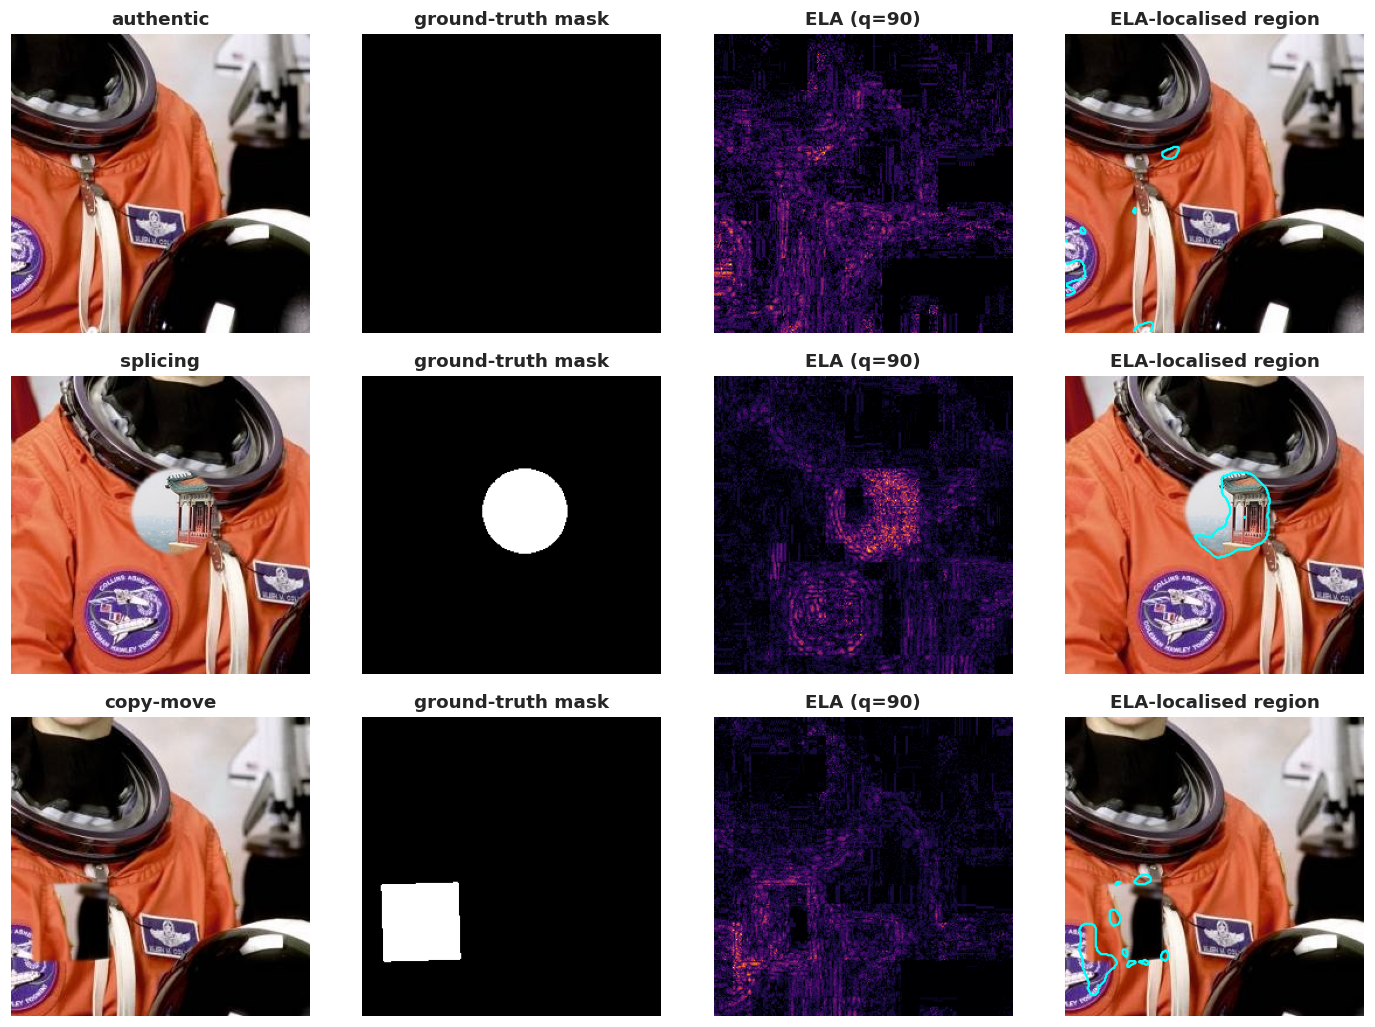

In [3]:
ex = {t: df[df.type==t].iloc[3] for t in ["authentic","splicing","copy-move"]}
fig, axes = plt.subplots(3, 4, figsize=(13, 9.5))
for r,(t,row) in enumerate(ex.items()):
    img = cv2.imread("data/"+row.file); gt = cv2.imread("data/"+row["mask"], 0)
    axes[r,0].imshow(rgb(img)); axes[r,0].set_title(f"{t}")
    axes[r,1].imshow(gt, cmap="gray"); axes[r,1].set_title("ground-truth mask")
    axes[r,2].imshow(ela_visual(img), cmap="inferno"); axes[r,2].set_title("ELA (q=90)")
    m = ela_map(img); axes[r,3].imshow(rgb(img)); axes[r,3].contour(localize(m)>0, colors="cyan", linewidths=1.5); axes[r,3].set_title("ELA-localised region")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); SAVE("01_examples_ela"); plt.show()

**How ELA works:** re-save the image as JPEG at a known quality and look at the difference. Regions with a *different compression history* from the rest react differently — a pasted region that never went through the q=70 compression stands out. A copy-move region shares its compression history with its surroundings, so ELA is the *wrong* tool for it in principle — it can only pick it up indirectly (rotation/rescaling resamples the patch, and blending alters local noise). That is why a second, geometry-based method is added.

## 2. Features
12 global ELA statistics, plus 7 **content-normalised** features: ELA relative to its local neighbourhood, high-frequency noise-residual statistics, and the correlation between ELA and image texture. ELA magnitude depends strongly on image content, so relative measures generalise better to unseen photos. (A first version with only the 12 raw ELA statistics reached 66% accuracy / 0.72 AUC in the same leave-one-source-out test; adding these features was a single experiment, chosen after seeing that result.)

In [4]:
F = pd.DataFrame([all_features(cv2.imread("data/"+f)) for f in df.file], columns=ALL_NAMES)
F["type"] = df.type; F["label"] = df.label
F.groupby("type")[["ela_mean","block_max","rel_ela_smooth_max","noise_peak_ratio"]].mean().round(2)

,ela_mean,block_max,rel_ela_smooth_max,noise_peak_ratio
type,,,,
authentic,1.05,4.06,1.66,12.14
copy-move,1.23,5.07,1.74,11.46
splicing,1.28,5.97,1.78,10.55


## 3. Splicing / forgery classifier — Random Forest
**Leave-One-Source-Out** cross-validation: the model is trained on 5 source photos and tested on the 6th, which it has never seen. A random image split would leak because crops from the same photo look alike.

In [5]:
X = F[ALL_NAMES].values; y = df.label.values; groups = df.source.values
oof = np.zeros(len(df)); fold_acc = {}
for tr, te in LeaveOneGroupOut().split(X, y, groups):
    clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1).fit(X[tr], y[tr])
    oof[te] = clf.predict_proba(X[te])[:,1]; fold_acc[groups[te][0]] = accuracy_score(y[te], oof[te]>=.5)
pred = (oof>=.5).astype(int)
print(pd.Series(fold_acc).round(3).to_frame("held-out accuracy"))

           held-out accuracy
astronaut              0.775
chelsea                0.870
china                  0.835
coffee                 0.760
flower                 0.575
rocket                 0.705


In [6]:
ela_res = pd.Series(dict(Accuracy=accuracy_score(y,pred), Precision=precision_score(y,pred), Recall=recall_score(y,pred), F1=f1_score(y,pred), ROC_AUC=roc_auc_score(y,oof))).round(3)
per_type = pd.Series({t: (pred[df.type==t]==df.label[df.type==t]).mean() for t in ["authentic","splicing","copy-move"]}).round(3)
print("ELA + Random Forest (leave-one-source-out)\n", ela_res.to_string(), "\n\nCorrectly classified, by image type:\n", per_type.to_string())

ELA + Random Forest (leave-one-source-out)
 Accuracy     0.753
Precision    0.711
Recall       0.855
F1           0.776
ROC_AUC      0.813 

Correctly classified, by image type:
 authentic    0.652
splicing     0.927
copy-move    0.783


## 4. Copy-move detector — SIFT self-matching + RANSAC
No training: keypoints are matched against *themselves*; matches between spatially distant points that agree on a single similarity transform (rotation/scale/shift) indicate a duplicated region. The number of RANSAC inliers is the score. Sensitivity to the ratio-test and inlier threshold:

In [7]:
sub = pd.concat([df[df.type=="authentic"], df[df.type=="copy-move"]])
imgs = {r.file: cv2.imread("data/"+r.file) for _, r in sub.iterrows()}
sweep = []
for ratio in (0.5, 0.6, 0.7):
    n = np.array([copy_move_detect(imgs[f], ratio=ratio)[0] for f in sub.file])
    for T in (3, 4, 6, 8):
        sweep.append(dict(ratio=ratio, min_inliers=T,
                          TPR_copy_move=round((n[sub.type.values=="copy-move"]>=T).mean(),3),
                          FPR_authentic=round((n[sub.type.values=="authentic"]>=T).mean(),3)))
pd.DataFrame(sweep).pivot(index="min_inliers", columns="ratio", values=["TPR_copy_move","FPR_authentic"])

TPR_copy_move               FPR_authentic              
ratio                 0.5    0.6    0.7           0.5    0.6    0.7
min_inliers                                                        
3                   0.493  0.550  0.603         0.007  0.057  0.133
4                   0.430  0.457  0.503         0.000  0.010  0.070
6                   0.327  0.357  0.380         0.000  0.000  0.018
8                   0.270  0.287  0.303         0.000  0.000  0.000

I use `ratio=0.6, min_inliers=4`: false positives stay at zero on authentic images while catching the most copy-moves. (This choice is made on the same images shown, so the TPR is slightly optimistic — a limitation stated below.)

Copy-move images detected: 45.7% | authentic images wrongly flagged: 1.0%


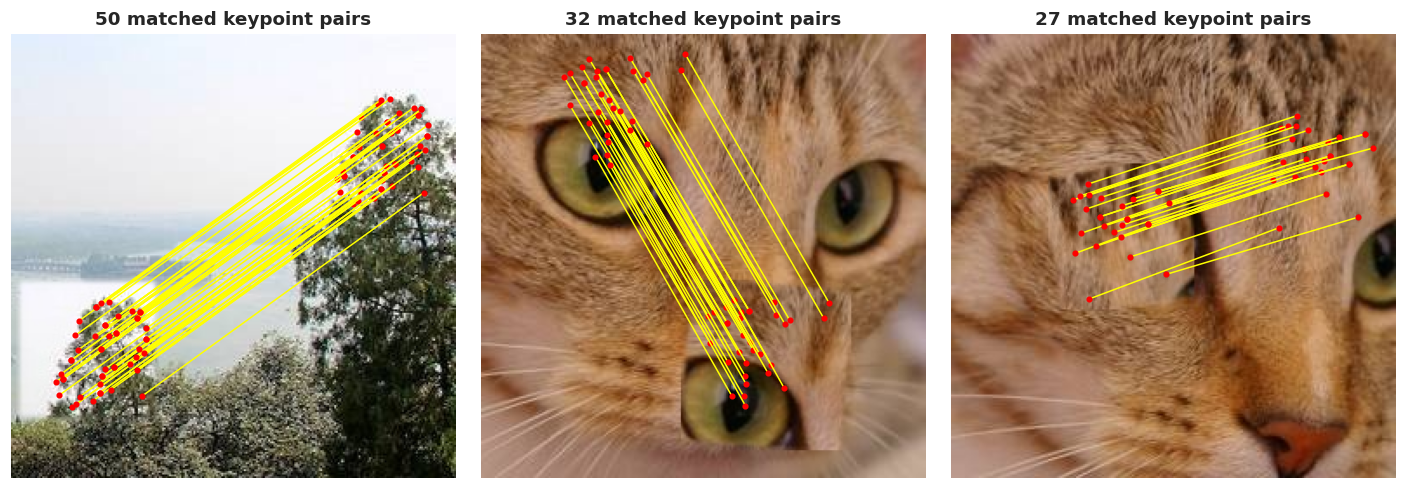

In [8]:
RATIO, MIN_INL = 0.6, 4
cm = {f: copy_move_detect(imgs[f], ratio=RATIO) for f in sub.file}
cm_score = pd.Series({f: v[0] for f, v in cm.items()})
print("Copy-move images detected:", f"{(cm_score[sub[sub.type=='copy-move'].file]>=MIN_INL).mean():.1%}",
      "| authentic images wrongly flagged:", f"{(cm_score[sub[sub.type=='authentic'].file]>=MIN_INL).mean():.1%}")
good = cm_score[sub[sub.type=="copy-move"].file].sort_values(ascending=False).index[[0, 6, 12]]
fig, axes = plt.subplots(1,3, figsize=(13,4.4))
for ax, f in zip(axes, good):
    n, s, d = cm[f]; ax.imshow(rgb(imgs[f])); ax.axis("off"); ax.set_title(f"{n} matched keypoint pairs")
    for a, b in zip(s, d): ax.plot([a[0], b[0]], [a[1], b[1]], "-", c="yellow", lw=1); ax.plot(*a, "o", c="red", ms=3); ax.plot(*b, "o", c="red", ms=3)
plt.tight_layout(); SAVE("02_copy_move_matches"); plt.show()

## 5. Combined detector
Flag an image as forged if **either** the ELA classifier fires (out-of-fold prediction) **or** the copy-move detector finds ≥ 4 consistent matches.

In [9]:
cm_all = np.array([ (cm_score[f] if f in cm_score.index else copy_move_detect(cv2.imread("data/"+f), ratio=RATIO)[0]) for f in df.file])
comb = ((pred==1) | (cm_all>=MIN_INL)).astype(int)
comb_res = pd.Series(dict(Accuracy=accuracy_score(y,comb), Precision=precision_score(y,comb), Recall=recall_score(y,comb), F1=f1_score(y,comb))).round(3)
by_type = pd.DataFrame({"ELA+RF only": pd.Series({t:(pred[df.type==t]==df.label[df.type==t]).mean() for t in ["authentic","splicing","copy-move"]}),
                        "Combined":    pd.Series({t:(comb[df.type==t]==df.label[df.type==t]).mean() for t in ["authentic","splicing","copy-move"]})}).round(3)
by_type.index.name = "correctly classified"
print(comb_res.to_string()); by_type

Accuracy     0.762
Precision    0.711
Recall       0.882
F1           0.787


,ELA+RF only,Combined
correctly classified,,
authentic,0.652,0.642
splicing,0.927,0.930
copy-move,0.783,0.833


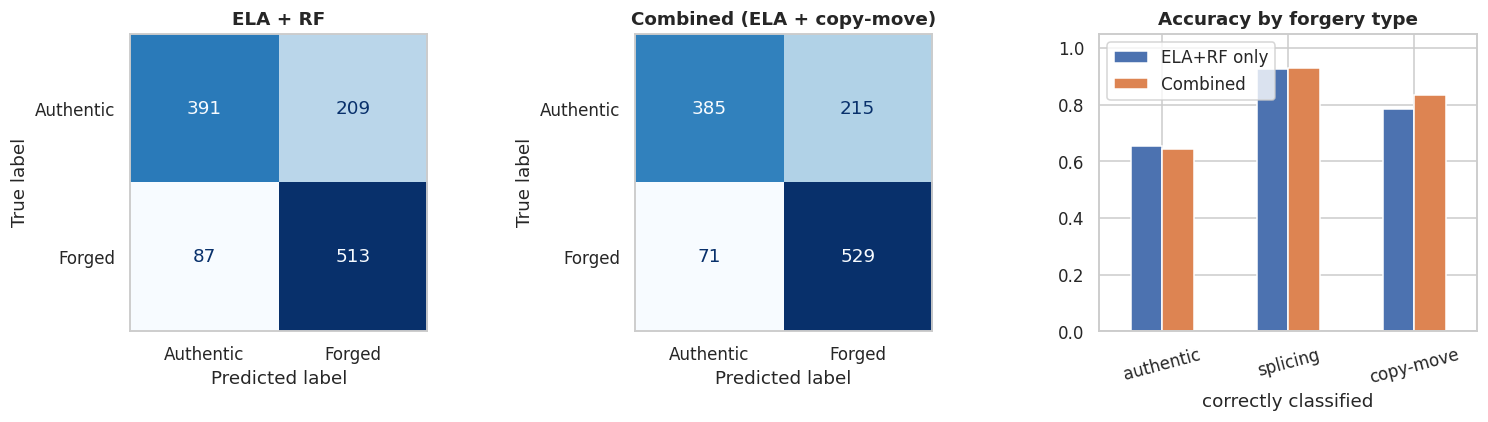

In [10]:
fig, axes = plt.subplots(1,3, figsize=(14,4))
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["Authentic","Forged"], cmap="Blues", ax=axes[0], colorbar=False); axes[0].set_title("ELA + RF"); axes[0].grid(False)
ConfusionMatrixDisplay.from_predictions(y, comb, display_labels=["Authentic","Forged"], cmap="Blues", ax=axes[1], colorbar=False); axes[1].set_title("Combined (ELA + copy-move)"); axes[1].grid(False)
by_type.plot.bar(ax=axes[2], rot=15); axes[2].set_ylim(0,1.05); axes[2].set_title("Accuracy by forgery type")
plt.tight_layout(); SAVE("03_results"); plt.show()

## 6. Localisation quality (splicing)
How well does the ELA map outline the pasted region? Measured with **IoU** against the ground-truth mask on spliced images.

Median IoU: 0.23 | mean IoU: 0.30 | images with IoU > 0.3: 41.3% | IoU > 0.5: 20.0%


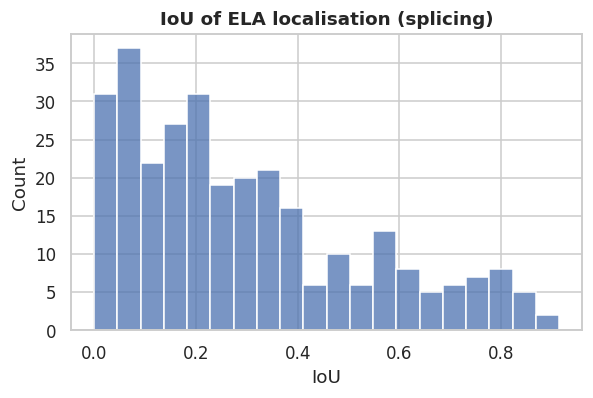

In [11]:
sp = df[df.type=="splicing"]; ious = []
for _, r in sp.iterrows():
    img = cv2.imread("data/"+r.file); gt = cv2.imread("data/"+r["mask"], 0)
    ious.append(iou(localize(ela_map(img)), gt))
ious = np.array(ious)
print(f"Median IoU: {np.median(ious):.2f} | mean IoU: {ious.mean():.2f} | images with IoU > 0.3: {(ious>.3).mean():.1%} | IoU > 0.5: {(ious>.5).mean():.1%}")
fig, ax = plt.subplots(figsize=(6,3.5)); sns.histplot(ious, bins=20, ax=ax); ax.set_title("IoU of ELA localisation (splicing)"); ax.set_xlabel("IoU")
SAVE("04_localisation_iou"); plt.show()

## 7. What does the classifier rely on?

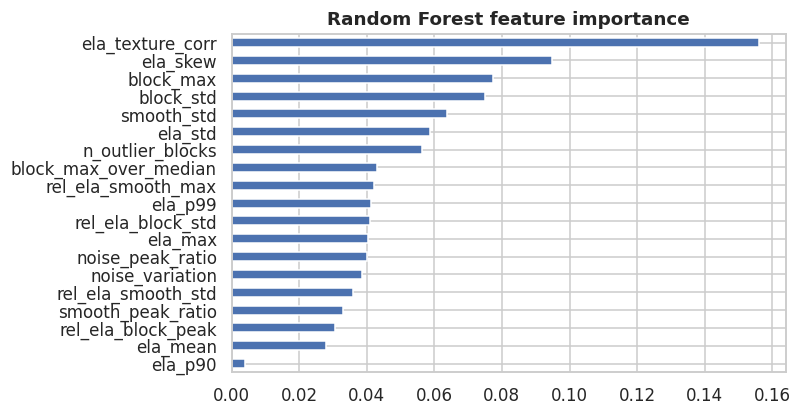

['models/ela_rf.joblib']

In [12]:
final = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1).fit(X, y)
imp = pd.Series(final.feature_importances_, index=ALL_NAMES).sort_values()
fig, ax = plt.subplots(figsize=(6.5,4)); imp.plot.barh(ax=ax, color="#4C72B0"); ax.set_title("Random Forest feature importance")
SAVE("05_feature_importance"); plt.show()
joblib.dump(final, "models/ela_rf.joblib")

## 8. Try it on a single image

In [13]:
def analyse(path):
    img = cv2.imread(path); m = ela_map(img)
    p = float(joblib.load("models/ela_rf.joblib").predict_proba(all_features(img)[None])[0,1])
    n, s, d = copy_move_detect(img, ratio=RATIO)
    verdict = "FORGED" if (p>=.5 or n>=MIN_INL) else "authentic"
    return dict(ELA_forgery_probability=round(p,3), copy_move_matches=n, verdict=verdict)
for t in ["authentic","splicing","copy-move"]:
    f = df[df.type==t].iloc[10].file; print(t.ljust(10), "→", analyse("data/"+f))

authentic  → {'ELA_forgery_probability': 0.05, 'copy_move_matches': 0, 'verdict': 'authentic'}
splicing   → {'ELA_forgery_probability': 0.999, 'copy_move_matches': 0, 'verdict': 'FORGED'}


copy-move  → {'ELA_forgery_probability': 0.918, 'copy_move_matches': 5, 'verdict': 'FORGED'}


## 9. Conclusions & limitations
- **ELA-based features work best on splicing** (different compression history), and pick up some copy-moves only indirectly; **keypoint matching covers copy-move** and rarely fires on authentic images. The two methods are complementary.
- **Overall accuracy is moderate**: the weakest class is *authentic* images, which the classifier falsely flags fairly often — ELA statistics vary a lot between photos, so an unseen photo can look 'suspicious' by chance. A real system would need a calibrated threshold chosen for an acceptable false-positive rate.
- Copy-move detection is the weak spot: small, low-texture patches produce few distinctive keypoints, so recall is moderate.
- **Synthetic benchmark:** every image shares one compression recipe (q=70 → q=95). Real-world forgeries involve unknown, varied histories, resizing, noise and re-saving, which degrade ELA considerably (ELA is known to be fragile). Real images would need external validation.
- Copy-move parameters were chosen on the evaluated set (no training involved, but TPR is slightly optimistic).
- Only 6 source photos, so generalisation to other scenes is not proven. Modern deep-learning approaches (e.g. noise-print / CNN-based detectors) would be the next step.